<div class='alert alert-block alert-info'>
<h1 align='center'>Logistic Regression & SGD</h1>
<h2 align='center'>Breast cancer dataset</h2>
<h3 align='center'>Using feature selection</h3>
</div>

# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score

# Loading Dataset

In [2]:
from sklearn.datasets import load_breast_cancer
bc=load_breast_cancer()
print(bc.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [3]:
print(bc.feature_names)
bc.target_names

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


array(['malignant', 'benign'], dtype='<U9')

In [4]:
x=bc.data
y=bc.target
print(f'''According to the dataset description, malignent data numbers are 212.
By getting shape from different class values we find the numerical value for each category.
for target=0 we have: {y[y==0].shape}
and for target=1 we have {y[y==1].shape}  ''')

According to the dataset description, malignent data numbers are 212.
By getting shape from different class values we find the numerical value for each category.
for target=0 we have: (212,)
and for target=1 we have (357,)  


In [5]:
bc_df=pd.DataFrame(x, columns=bc.feature_names)
bc_df=bc_df.assign(Diagnosis=y)
bc_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


# EDA

## Feature selection

In [6]:
correlation_matrix=bc_df.corr()
#class 1 is for benign and we want class 0 which is malignent.
# so the corrlation coeficient is probably minus.
selected_features=correlation_matrix[correlation_matrix.Diagnosis<=-0.5].index 

# By using minus correlation coeficient we lose the 'Diagnosis' row itself.
# so we will add the row manually.
indexs=list(selected_features)
indexs.append('Diagnosis')
selected_corr_matrix=correlation_matrix.loc[indexs, indexs]

<Axes: >

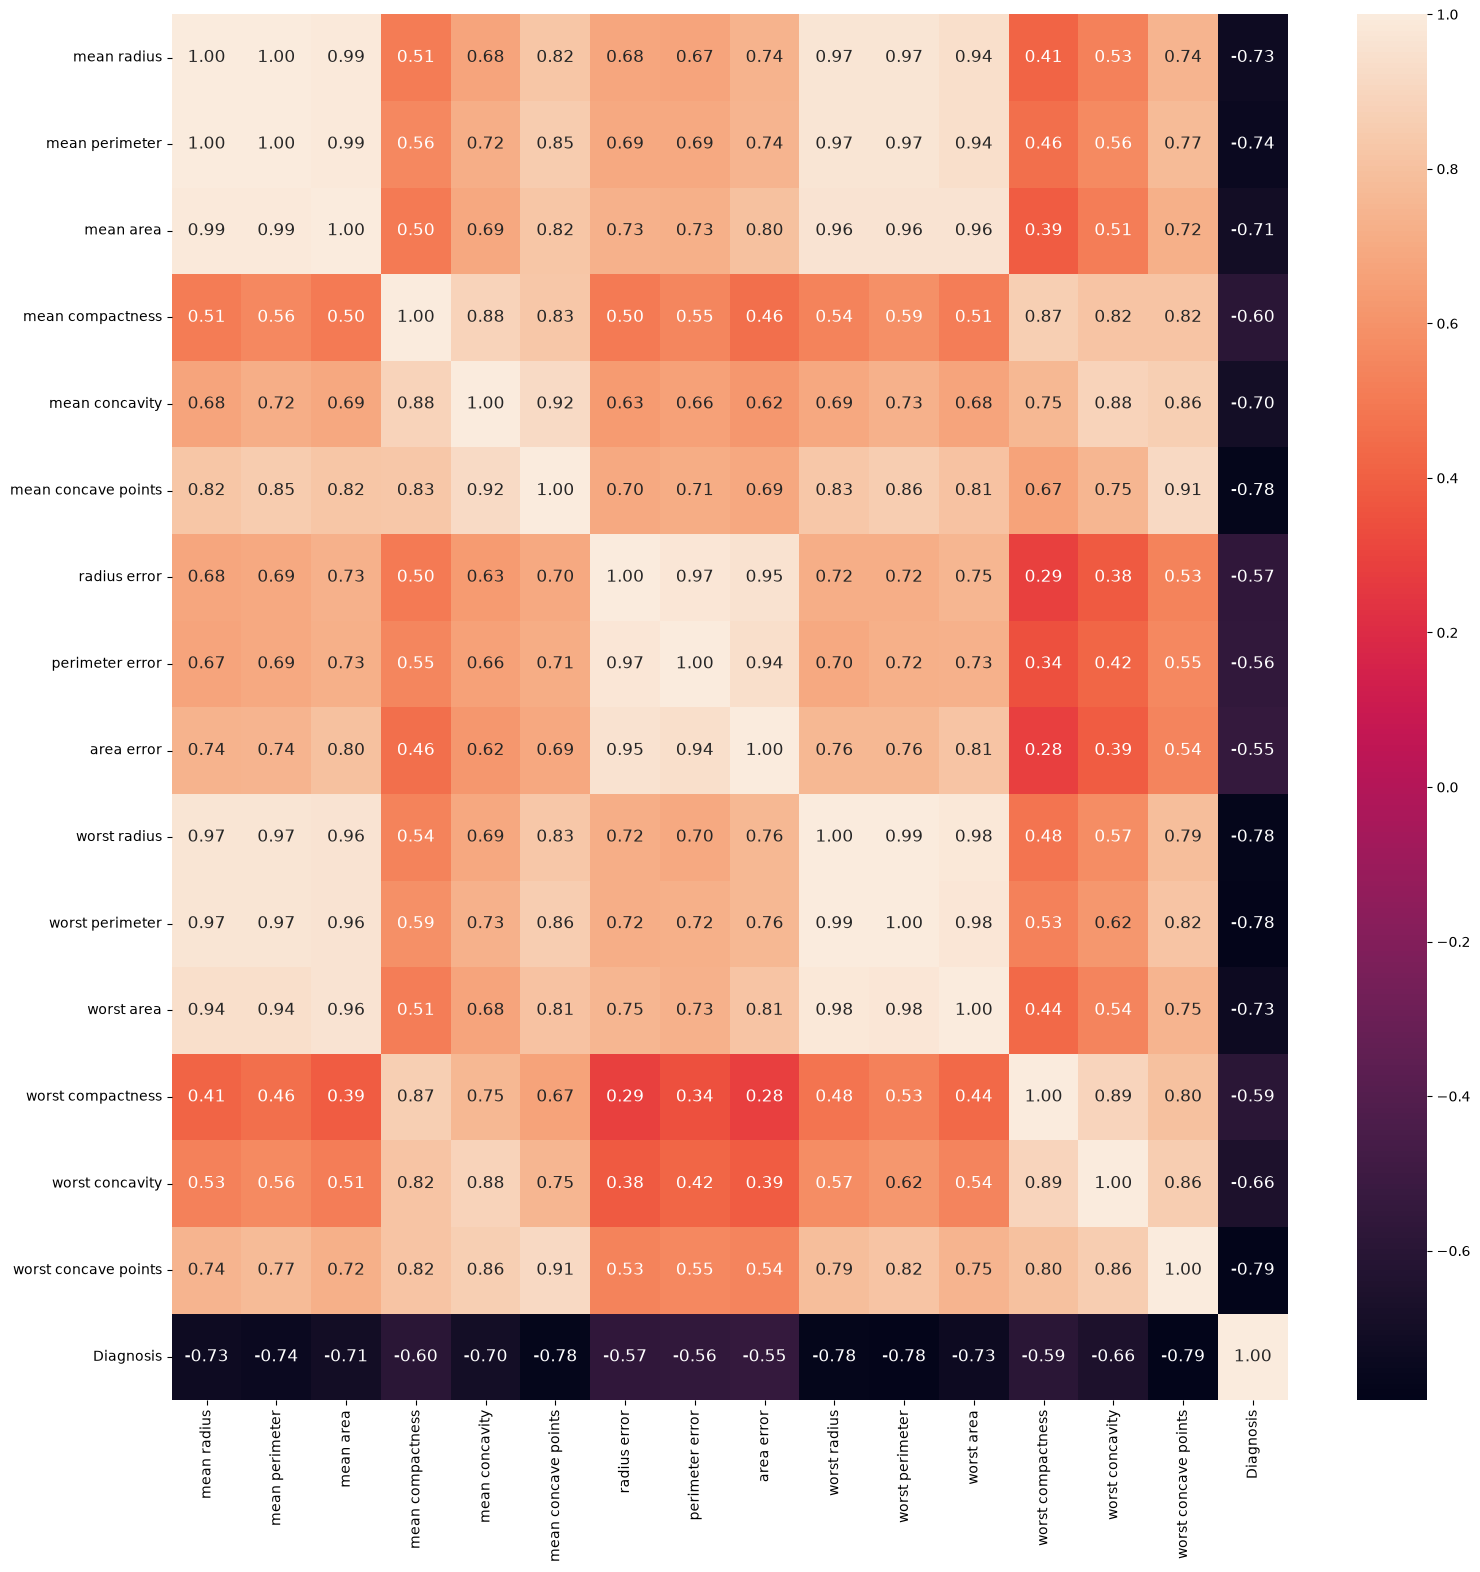

In [7]:
plt.figure(figsize=(18,18))
plt.xlabel(xlabel=indexs, fontdict={'size':15})
plt.ylabel(ylabel=indexs, fontdict={'size':15})
sns.heatmap(selected_corr_matrix, annot=True, annot_kws={'size':12}, fmt='.2f')

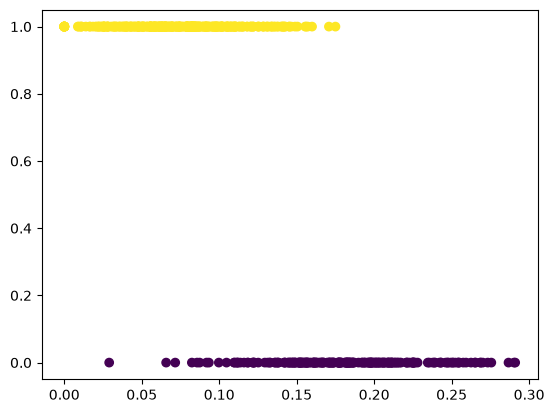

In [8]:
plt.scatter(bc_df['worst concave points'], bc_df['Diagnosis'], c=bc_df.Diagnosis)

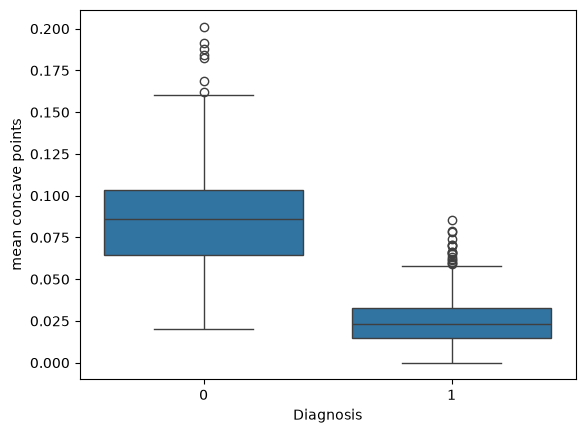

In [9]:
sns.boxplot(x='Diagnosis', y='mean concave points', data=bc_df)
plt.show()

# Data Spliting

In [10]:
x_train, x_test, y_train, y_test=train_test_split(bc_df[indexs],
                                                  bc_df['Diagnosis'],
                                                  test_size=0.2, random_state=42)

# Model Selection

In [11]:
LR=LogisticRegression(max_iter=10000, random_state=42)
SG=SGDClassifier(loss='log_loss', random_state=42)

# Feature Scaling

In [12]:
sc=StandardScaler()
x_train_scaled=sc.fit_transform(x_train)
x_test_scaled=sc.transform(x_test)

# Training Model

## with Scaled Features

In [13]:
LR.fit(x_train_scaled, y_train)
SG.fit(x_train_scaled, y_train)

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; onl

## whitout scaled Features

In [14]:
LR_ns=LogisticRegression(max_iter=10000, random_state=42)
SG_ns=SGDClassifier(loss='log_loss', random_state=42)

LR_ns.fit(x_train, y_train)
SG_ns.fit(x_train, y_train)

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; onl

# Model Evaluation

## with scaled features

In [15]:
LR_train_accuracy=LR.score(x_train_scaled, y_train)
LR_test_accuracy=LR.score(x_test_scaled, y_test)

SG_train_accuracy=SG.score(x_train_scaled, y_train)
SG_test_accuracy=SG.score(x_test_scaled, y_test)

print(f'''Accuracy of Linear Regression model for scaled data: 
train accuracy:{LR_train_accuracy}
test accuracy: {LR_test_accuracy}\n''')

print(f'''Accuracy of Stocastic Gradient descent model for scaled data: 
train accuracy:{SG_train_accuracy}
test accuracy: {SG_test_accuracy}''')

Accuracy of Linear Regression model for scaled data: 
train accuracy:1.0
test accuracy: 1.0

Accuracy of Stocastic Gradient descent model for scaled data: 
train accuracy:1.0
test accuracy: 1.0


## without scaled features

In [16]:
LR_train_accuracy_ns=LR_ns.score(x_train, y_train)
LR_test_accuracy_ns=LR_ns.score(x_test, y_test)

SG_train_accuracy_ns=SG_ns.score(x_train, y_train)
SG_test_accuracy_ns=SG_ns.score(x_test, y_test)

print(f'''Accuracy of Linear Regression model for not scaled data: 
train accuracy:{LR_train_accuracy_ns}
test accuracy: {LR_test_accuracy_ns}\n''')

print(f'''Accuracy of Stocastic Gradient descent model for not scaled data: 
train accuracy:{SG_train_accuracy_ns:.2f}
test accuracy: {SG_test_accuracy_ns:.2f}''')

Accuracy of Linear Regression model for not scaled data: 
train accuracy:1.0
test accuracy: 1.0

Accuracy of Stocastic Gradient descent model for not scaled data: 
train accuracy:0.79
test accuracy: 0.84


# Difference between scaled and not scaled features

In [17]:
train_dict={'Linear Regression (scaled data)':LR_train_accuracy,
                 'Linear Regression':LR_train_accuracy_ns,
                 'Stocastic Gradient descent (scaled data)':SG_train_accuracy,
                 'Stocastic Gradient descent':round(SG_train_accuracy_ns,2)}
                 
test_dict={'Linear Regression (scaled data)':LR_test_accuracy,
                 'Linear Regression':LR_test_accuracy_ns,
                 'Stocastic Gradient descent (scaled data)':SG_test_accuracy,
                 'Stocastic Gradient descent':round(SG_test_accuracy_ns,2)}

evaluation_dict={'Train Accuracy':train_dict,
                 'Test Accuracy':test_dict}
evaluation_df=pd.DataFrame( evaluation_dict)
print(evaluation_df)

                                          Train Accuracy  Test Accuracy
Linear Regression (scaled data)                     1.00           1.00
Linear Regression                                   1.00           1.00
Stocastic Gradient descent (scaled data)            1.00           1.00
Stocastic Gradient descent                          0.79           0.84


# Decision Boundary plot

## Manually

In [18]:
wanted_features=bc_df[['worst perimeter','worst concave points']]
f1_min, f2_min=wanted_features.min(axis=0)
f1_max, f2_max=wanted_features.max(axis=0)

n=300
f1_r = np.linspace(f1_min, f1_max, n)
f2_r = np.linspace(f2_min, f2_max, n)

f1_m, f2_m = np.meshgrid(f1_r,f2_r)
fm=np.stack((f1_m.flatten(), f2_m.flatten()), axis=1)

In [19]:
LR_d=LogisticRegression(max_iter=10000, random_state=42)
SG_d=SGDClassifier(loss='log_loss', random_state=42)

LR_d.fit(wanted_features.values, y)
SG_d.fit(wanted_features.values, y)

ym_LR=LR_d.decision_function(fm)
ym_SG=SG_d.decision_function(fm)

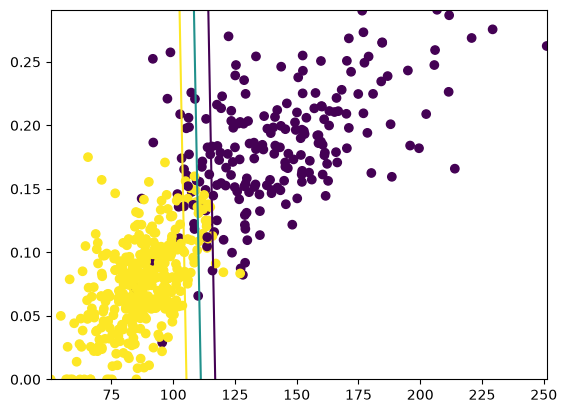

In [20]:
plt.scatter(wanted_features.iloc[:,0], wanted_features.iloc[:,1],c=y)
plt.contour(f1_m, f2_m, ym_LR.reshape(f1_m.shape), levels=[-1,0,1])

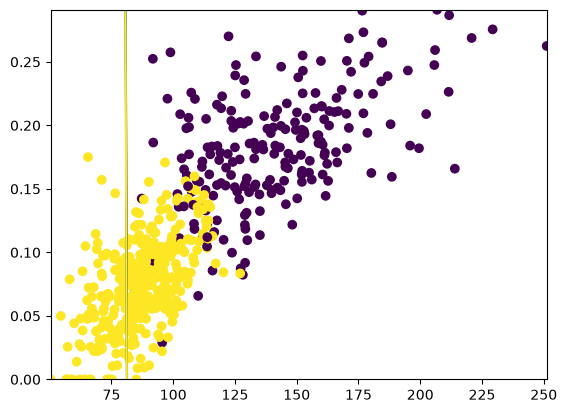

In [21]:
plt.scatter(wanted_features.iloc[:,0], wanted_features.iloc[:,1],c=y)
plt.contour(f1_m, f2_m, ym_SG.reshape(f1_m.shape), levels=[-2,0,2])

## Using mlxtend library 

<Axes: >

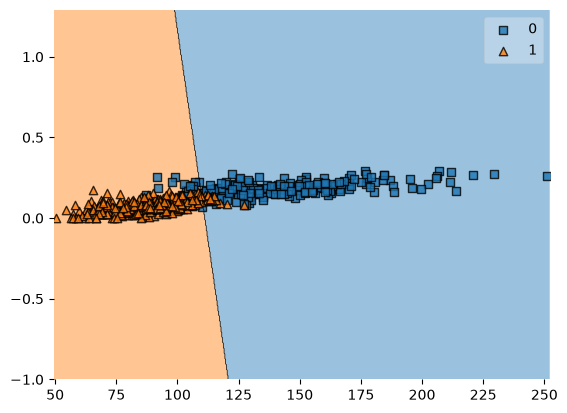

In [28]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(wanted_features.values, y, clf=LR_d)

<Axes: >

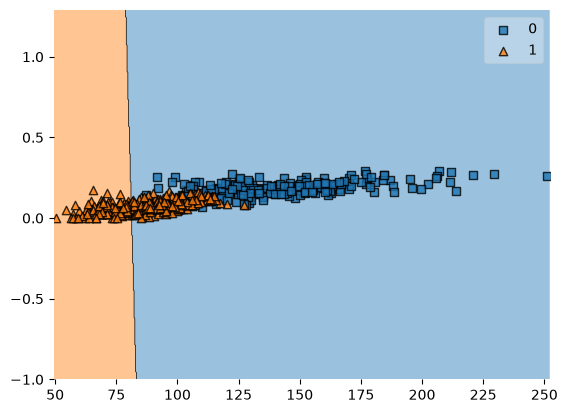

In [26]:
plot_decision_regions(wanted_features.values,y, clf=SG_d)